# Ejercicio 3: exploración adaptativa

En el Ejercicio 2, ε baja 1/150 por episodio: el agente explora lo mismo si ya ha aprendido el TWAP en el episodio 20 que si no lo ha aprendido en el 140. El número de episodios es arbitrario y no tiene relación con lo que el agente sabe. Aquí ε pasa a depender del **rendimiento del agente frente a un benchmark**, como se propuso en clase, y no del número de episodios jugados (se mantiene un número fijo de episodios, como permite el enunciado).

## Bloques modificados

| Bloque | Cambio | Fichero |
|---|---|---|
| Esquema de ε | `AdaptiveEpsilon` sustituye al decaimiento lineal (`LinearEpsilonDecay`, que se conserva como referencia) | `exploration.py` |
| Bucle | `train_with_evaluation` llama a `scheduler.on_episode_end()` (en el esquema adaptativo no cambia ε) y, tras cada evaluación, a `scheduler.on_evaluation(ratio)` | `train.py` |

## 1. ¿Cómo se determina que el algoritmo ha mejorado?

* **Qué se mide.** El desvío medio frente al plan (en títulos) de la **política greedy**, sin exploración. La recompensa de entrenamiento no sirve: mezcla lo aprendido con el ruido de las acciones aleatorias, que depende de la propia ε.
* **Sobre qué.** Un **panel fijo** de 20 episodios de train (mismo día, hora, duración y tamaño en cada evaluación, gracias a `reset(seed)`). Así dos evaluaciones son comparables: si el número baja es porque la política es mejor, no porque haya tocado un episodio fácil.
* **Contra qué.** El **TWAP determinista** sobre esos mismos episodios: `ratio = desvío agente / desvío TWAP`. El benchmark da escala al número (un desvío de 0,4 títulos no dice nada por sí solo) y define cuándo el agente es "suficientemente bueno".
* **Cada cuánto.** Cada 5 episodios (unos 2 500 steps).

## 2. ¿Cómo se traslada esa mejora a ε?

Con un **nivel de aspiración** `A`, que empieza en 1 (igualar al TWAP):

$$\varepsilon^{*} = \varepsilon_{min} + (\varepsilon_{max} - \varepsilon_{min}) \cdot \operatorname{clip}\left(\frac{\log(\text{ratio}/A)}{\log(\text{ratio}_{max}/A)},\ 0,\ 1\right), \qquad \varepsilon \leftarrow \tfrac{1}{2}\,\varepsilon + \tfrac{1}{2}\,\varepsilon^{*}$$

* Lejos del benchmark (ratio ≥ 10) se explora al máximo; al alcanzar la aspiración, ε cae a su suelo (0,02). Entre ambos extremos la interpolación es logarítmica porque el error recorre varios órdenes de magnitud (de ~25 títulos con la red sin entrenar a ~0,25).
* **Aspiración que se endurece.** Tras cada evaluación, `A = min(1, mejor mediana de 3 evaluaciones seguidas · 1,1)`. Una vez superado el TWAP, el listón pasa a ser el mejor resultado propio con un 10 % de holgura. Se usa la mediana y no el mínimo porque el panel es finito: una evaluación afortunada fijaría un listón que el agente no puede sostener y haría subir ε sin que haya empeorado.
* **Si empeora, vuelve a explorar.** ε no es monótona: si el ratio se deteriora (olvido catastrófico, cambio de datos), ε sube otra vez. Es la respuesta natural a un problema no estacionario.
* **Suavizado.** Media con el valor anterior, para que una evaluación ruidosa no mueva ε de golpe.
* Entre evaluaciones ε no cambia: jugar más episodios no aporta, por sí solo, información sobre si se ha aprendido.

In [1]:
from pathlib import Path
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# src al path, relativo a la raíz del repositorio
repo_root = Path.cwd().resolve()
if not (repo_root / "src").exists():
    repo_root = repo_root.parent
if str(repo_root / "src") not in sys.path:
    sys.path.insert(0, str(repo_root / "src"))

from execution_rl import *  # noqa: F403
from execution_rl.experiments import (
    PANEL_SEEDS,
    ExperimentConfig,
    build_agent,
    build_env,
    build_scheduler,
    eval_curves,
    restore_agent,
    run_many,
    save_results_table,
    twap_panel,
    with_seeds,
)

SEED = 42
set_seeds(SEED)
results_dir = repo_root / "results"
results_dir.mkdir(parents=True, exist_ok=True)
# procesos para los barridos con varias semillas
N_JOBS = max(1, min(12, (os.cpu_count() or 2) - 2))
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print(f"Procesos en paralelo: {N_JOBS}")

Procesos en paralelo: 12


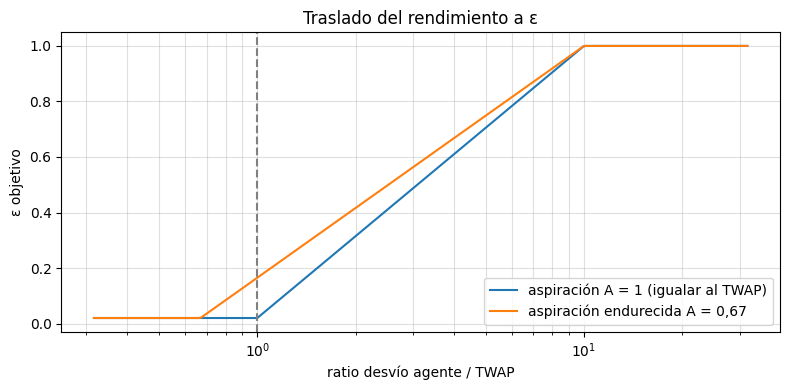

In [2]:
sch = AdaptiveEpsilon()
ratios = np.logspace(-0.5, 1.5, 300)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ratios, [sch.target_epsilon(r) for r in ratios], label="aspiración A = 1 (igualar al TWAP)")
sch.aspiration = 0.67
ax.plot(ratios, [sch.target_epsilon(r) for r in ratios], label="aspiración endurecida A = 0,67")
ax.axvline(1.0, color="grey", ls="--")
ax.set_xscale("log")
ax.set_xlabel("ratio desvío agente / TWAP")
ax.set_ylabel("ε objetivo")
ax.set_title("Traslado del rendimiento a ε")
ax.grid(True, which="both", alpha=0.4)
ax.legend()
fig.tight_layout()
fig.savefig(results_dir / "ej3_epsilon_mapping.png", dpi=150, bbox_inches="tight")
plt.show()

## Comparación: ε lineal frente a ε adaptativa

Misma configuración del Ejercicio 2, 150 episodios y 5 semillas por esquema. Solo cambia el esquema de ε.

In [3]:
base = ExperimentConfig(name="ε lineal (Ej. 2)")
seeds = [0, 1, 2, 3, 4]
configs = with_seeds(base, seeds) + with_seeds(base, seeds, name="ε adaptativa", epsilon="adaptive", eps_min=0.02)
results = run_many(configs, n_jobs=N_JOBS)
curves = eval_curves(results)
save_results_table(curves, results_dir / "ej3_curves.csv")

train_rows = []
for r in results:
    for ep, (rew, eps) in enumerate(zip(r["history"]["rewards"], r["history"]["epsilons"])):
        train_rows.append({"name": r["config"]["name"], "seed": r["config"]["seed"], "episode": ep, "reward": rew, "epsilon": eps})
train_df = pd.DataFrame(train_rows)
print(f"{len(results)} entrenamientos completados")

10 entrenamientos completados


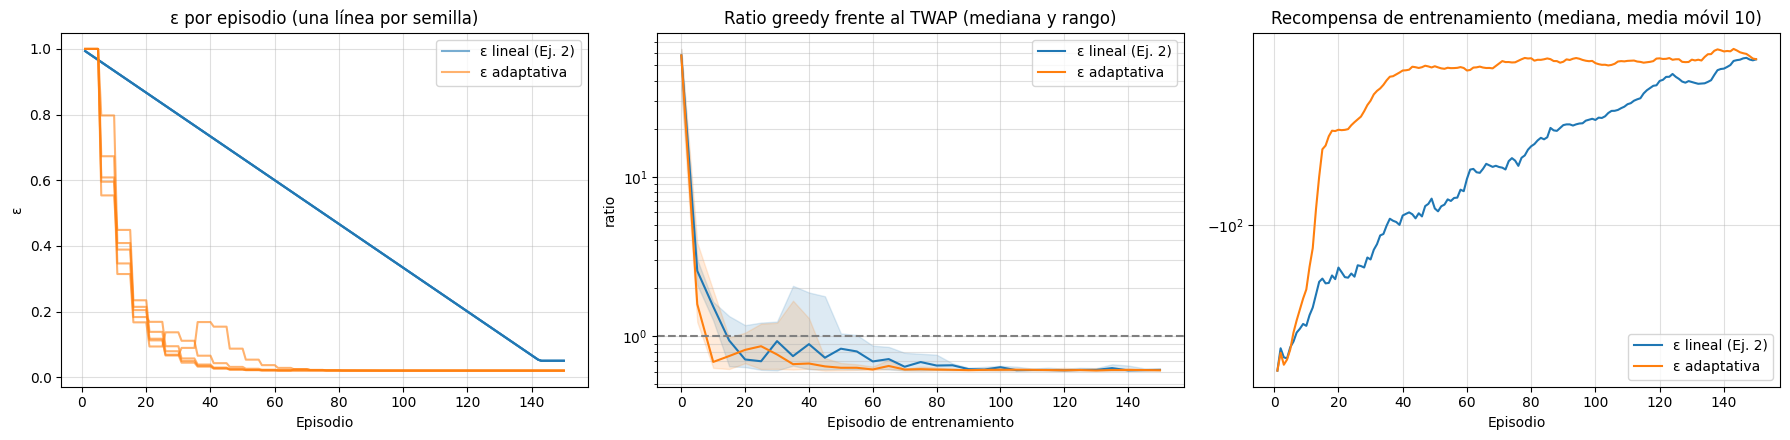

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for name, g in train_df.groupby("name", sort=False):
    for sd, gs in g.groupby("seed"):
        axes[0].plot(gs["episode"] + 1, gs["epsilon"], color="C0" if "lineal" in name else "C1", alpha=0.6,
                     label=name if sd == 0 else None)
axes[0].set_title("ε por episodio (una línea por semilla)")
axes[0].set_xlabel("Episodio")
axes[0].set_ylabel("ε")
axes[0].grid(True, alpha=0.4)
axes[0].legend()

plot_eval_curves(curves, "ratio", ax=axes[1], logy=True, title="Ratio greedy frente al TWAP (mediana y rango)")
axes[1].axhline(1.0, color="grey", ls="--")

for name, g in train_df.groupby("name", sort=False):
    med = g.groupby("episode")["reward"].median().rolling(10, min_periods=1).mean()
    axes[2].plot(med.index + 1, med, label=name)
axes[2].set_yscale("symlog")
axes[2].set_title("Recompensa de entrenamiento (mediana, media móvil 10)")
axes[2].set_xlabel("Episodio")
axes[2].grid(True, which="both", alpha=0.4)
axes[2].legend()
fig.tight_layout()
fig.savefig(results_dir / "ej3_epsilon_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
def first_episode(g: pd.DataFrame, col: str, cond) -> float:
    hit = g.loc[cond(g[col]), "episode"]
    return float(hit.iloc[0] + 1) if len(hit) else np.nan


per_seed = []
for (name, sd), g in curves.groupby(["name", "seed"], sort=False):
    t = train_df[(train_df["name"] == name) & (train_df["seed"] == sd)]
    per_seed.append({
        "esquema": name,
        "semilla": sd,
        "iguala al TWAP (episodio)": first_episode(g, "ratio", lambda s: s <= 1.0),
        "ε <= 0,1 (episodio)": first_episode(t, "epsilon", lambda s: s <= 0.1),
        "recompensa media de entrenamiento": t["reward"].mean(),
        "ratio final": g["ratio"].iloc[-1],
    })
per_seed = pd.DataFrame(per_seed)
save_results_table(per_seed, results_dir / "ej3_summary.csv")
display(per_seed)
per_seed.groupby("esquema", sort=False).median(numeric_only=True).drop(columns="semilla")

,esquema,semilla,iguala al TWAP (episodio),"ε <= 0,1 (episodio)",recompensa media de entrenamiento,ratio final
0,ε lineal (Ej. 2),0,35.000,135.000,-87.645,0.610
1,ε lineal (Ej. 2),1,15.000,135.000,-75.322,0.610
2,ε lineal (Ej. 2),2,15.000,135.000,-80.998,0.615
3,ε lineal (Ej. 2),3,15.000,135.000,-82.774,0.626
4,ε lineal (Ej. 2),4,20.000,135.000,-74.355,0.617
5,ε adaptativa,0,15.000,26.000,-40.009,0.626
6,ε adaptativa,1,10.000,26.000,-39.147,0.609
7,ε adaptativa,2,10.000,21.000,-41.569,0.612
8,ε adaptativa,3,10.000,26.000,-38.884,0.610
9,ε adaptativa,4,15.000,26.000,-42.939,0.625


,iguala al TWAP (episodio),"ε <= 0,1 (episodio)",recompensa media de entrenamiento,ratio final
esquema,,,,
ε lineal (Ej. 2),15.000,135.000,-80.998,0.615
ε adaptativa,10.000,26.000,-40.009,0.612


## Lectura de los resultados

* Con ε lineal, el agente iguala al TWAP hacia el episodio 15 (mediana), pero ε no baja de 0,1 hasta el episodio 135 en todas las semillas: durante casi todo el entrenamiento se siguen tomando acciones aleatorias que ya no aportan.
* Con ε adaptativa, ε baja de 0,1 entre los episodios 21 y 26, justo después de que **cada** política alcance la aspiración. El número de episodios de exploración lo decide el aprendizaje, no un parámetro fijado de antemano.
* ε no es monótona: en una de las semillas la política greedy empeora hacia los episodios 35 a 45 y ε vuelve a subir (hasta ~0,17), para bajar otra vez cuando se recupera. Es la respuesta prevista ante un deterioro.
* La recompensa media de entrenamiento (que incluye el coste de explorar) pasa de unos -81 a unos -40, la mitad, y la calidad final de la política greedy es la misma (ratio 0,61 en ambos): se gasta menos en exploración inútil sin perder aprendizaje.
* El mismo criterio (ratio frente al benchmark sobre un panel fijo) sirve para decidir cuándo parar de entrenar y qué pesos guardar: es la base de la idea C del Ejercicio 4.

**Limitaciones.** La evaluación cuesta 20 episodios greedy cada 5 de entrenamiento. Además, el criterio solo mide el seguimiento del plan: si el objetivo incluye precio (idea A del Ejercicio 4), el ratio debe incluir también esa dimensión.